In [20]:
import torch
import matplotlib.pyplot as plt

In [21]:
# Genera vettori casuali con valori componenti tra 1 e 10, NORMALIZZATI!
def generate_sample(seq_len=7):
    x = torch.zeros(seq_len, 1)

    position = torch.randint(low=0, high=seq_len, size=(1,)).item()

    raw_value = torch.randint(low=1, high=10, size=(1,)).float()

    # normalizzazione
    value = raw_value / 9.0
    
    x[position, 0] = value

    y = value.clone()

    return x, y, position

In [22]:
for _ in range(5):
    xs, ys, pos = generate_sample()

    print("x =", xs.squeeze().tolist(), "| target =", ys.item(), "| posizione =", pos)

x = [0.0, 0.0, 0.0, 0.0, 0.8888888955116272, 0.0, 0.0] | target = 0.8888888955116272 | posizione = 4
x = [0.0, 0.0, 0.0, 0.0, 1.0, 0.0, 0.0] | target = 1.0 | posizione = 4
x = [0.0, 0.0, 0.0, 0.0, 0.0, 0.4444444477558136, 0.0] | target = 0.4444444477558136 | posizione = 5
x = [0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.6666666865348816] | target = 0.6666666865348816 | posizione = 6
x = [0.0, 0.0, 0.0, 0.0, 0.0, 0.7777777910232544, 0.0] | target = 0.7777777910232544 | posizione = 5


In [23]:
torch.manual_seed(42)
input_size = 1
hidden_size = 8 # hidden layer più ampio
output_size = 1

# Weights
Wx = (torch.randn(hidden_size, 1) * 0.1).requires_grad_()
Wh = (torch.randn(hidden_size, hidden_size) * 0.1).requires_grad_()
b = torch.zeros(hidden_size, requires_grad=True)
Wy = (torch.randn(output_size, hidden_size) * 0.1).requires_grad_()
by = torch.zeros(output_size, requires_grad=True)

In [24]:
def forward_4d(x):
    h = torch.zeros(hidden_size)
    states = []

    for t in range(len(x)):
        h = torch.tanh(Wx @ x[t] + Wh @ h + b)
        states.append(h)

    y_hat = Wy @ h + by

    return y_hat, states

In [62]:
# Analogo per n-dim
def forward_rnn(x):
    h = torch.zeros(hidden_size)

    states = []

    for t in range(len(x)):
        h = torch.tanh(Wx @ x[t] + Wh @ h + b)

        states.append(h)

    y_hat = Wy @ h + by

    return y_hat, states

In [7]:
lr = 0.01

for epoch in range(5000):
    x_train, y_train, _ = generate_sample()
    y_hat, states = forward_4d(x_train)
    loss = ((y_hat - y_train) ** 2).mean()
    loss.backward()

    with torch.no_grad():
        Wx -= lr * Wx.grad
        Wh -= lr * Wh.grad
        b -= lr * b.grad
        Wy -= lr * Wy.grad
        by -= lr * by.grad

    Wx.grad.zero_()
    Wh.grad.zero_()
    b.grad.zero_()
    Wy.grad.zero_()
    by.grad.zero_()

    if epoch % 500 == 0:
        print(f"Epoch {epoch:4d} | "
            f"Loss = {loss.item():.6f} | "
            f"Prediction = {y_hat.item():.6f}")

Epoch    0 | Loss = 1.043067 | Prediction = -0.021306
Epoch  500 | Loss = 6.222793 | Prediction = 6.494553
Epoch 1000 | Loss = 4.841703 | Prediction = 5.200387
Epoch 1500 | Loss = 2.016139 | Prediction = 4.419908


KeyboardInterrupt: 

In [8]:
# 100 esempi
errors = []

for _ in range(100):
    x_test, y_test, pos = generate_sample()

    with torch.no_grad():
        pred, _ = forward_4d(x_test)

    error = abs(pred.item() - y_test.item())

    errors.append(error)

print("Errore medio test:", sum(errors) / len(errors))

Errore medio test: 2.324148344993591


In [25]:
# Aumentare il numero di sequenze prima di un update
def generate_batch(batch_size=64, seq_len=7):
    xs = []
    ys = []

    for _ in range(batch_size):
        x_sample, y_sample, _ = generate_sample(seq_len)
        xs.append(x_sample)
        ys.append(y_sample)

    return xs, ys

In [26]:
params = [Wx, Wh, b, Wy, by]

optimizer = torch.optim.Adam(params, lr=0.003)

In [28]:
# Calcolo della loss media per ogni epoch
#lr = 0.005
batch_size = 64

for epoch in range(3000):
    optimizer.zero_grad()

    xs, ys = generate_batch(batch_size)

    total_loss = 0

    for x_train, y_train in zip(xs, ys):
        y_hat, _ = forward_4d(x_train)
        loss = ((y_hat - y_train) ** 2).mean()
        total_loss = total_loss + loss

    total_loss = total_loss / batch_size
    
    total_loss.backward()

    # Gradient clipping
    torch.nn.utils.clip_grad_norm_([Wx, Wh, b, Wy, by], max_norm=1.0)

    optimizer.step()
    """
    with torch.no_grad():
        Wx -= lr * Wx.grad
        Wh -= lr * Wh.grad
        b -= lr * b.grad
        Wy -= lr * Wy.grad
        by -= lr * by.grad

    Wx.grad.zero_()
    Wh.grad.zero_()
    b.grad.zero_()
    Wy.grad.zero_()
    by.grad.zero_()
    """
    if epoch % 250 == 0:
        print(f"Epoch {epoch:4d} | "
            f"Loss = {total_loss.item():.6f}"
        )

Epoch    0 | Loss = 0.425048
Epoch  250 | Loss = 0.002192
Epoch  500 | Loss = 0.001030
Epoch  750 | Loss = 0.000571
Epoch 1000 | Loss = 0.000494
Epoch 1250 | Loss = 0.000305
Epoch 1500 | Loss = 0.000264
Epoch 1750 | Loss = 0.000167
Epoch 2000 | Loss = 0.000231
Epoch 2250 | Loss = 0.000134
Epoch 2500 | Loss = 0.000114
Epoch 2750 | Loss = 0.000117


KeyboardInterrupt: 

In [30]:
position_errors = {i: [] for i in range(7)}
errors = []

for _ in range(1000):
    x_test, y_test, pos = generate_sample()

    with torch.no_grad():
        pred, _ = forward_4d(x_test)

    pred_original = pred.item() * 9
    target_original = y_test.item() * 9

    error = abs(pred_original - target_original)

    position_errors[pos].append(error)
    errors.append(error)

for pos in range(7):
    avg_error = sum(position_errors[pos]) / len(position_errors[pos])

    print(f"Posizione {pos} | " f"Errore medio = {avg_error:.4f}")

print("MAE scala originale:", sum(errors) / len(errors))

Posizione 0 | Errore medio = 0.1204
Posizione 1 | Errore medio = 0.0917
Posizione 2 | Errore medio = 0.0771
Posizione 3 | Errore medio = 0.0529
Posizione 4 | Errore medio = 0.0512
Posizione 5 | Errore medio = 0.0426
Posizione 6 | Errore medio = 0.0459
MAE scala originale: 0.06901504522562027


In [14]:
# Controllo se il problema è tanh che fa collassare i valori di Wxx_t attorno alla media
for value in range(1, 10):
    x_test = torch.zeros(7, 1)
    x_test[6, 0] = float(value)

    with torch.no_grad():
        pred, _ = forward_4d(x_test)

    print(f"Target {value} -> " f"Prediction {pred.item():.4f}")

Target 1 -> Prediction 4.0785
Target 2 -> Prediction 4.3893
Target 3 -> Prediction 4.6800
Target 4 -> Prediction 4.9224
Target 5 -> Prediction 5.1185
Target 6 -> Prediction 5.2740
Target 7 -> Prediction 5.3953
Target 8 -> Prediction 5.4887
Target 9 -> Prediction 5.5600


In [32]:
baseline_errors = []

for _ in range(5000):
    _, y_test, _ = generate_sample()
    target_original = y_test.item() * 9.0

    # predittore stupido, sempre 5
    baseline_prediction = 5.0

    baseline_errors.append(abs(baseline_prediction - target_original))

print("MAE baseline:", sum(baseline_errors) / len(baseline_errors))

MAE baseline: 2.2406000494435427


In [33]:
# Prendiamo lo stesso numero e cambiamolo solo di posizione in X
def make_probe(position, value=7.0):
    x_probe = torch.zeros(7, 1)
    x_probe[position, 0] = value / 9.0
    y_probe = torch.tensor([value / 9.0])

    return x_probe, y_probe

In [63]:
def make_long_probe(seq_len, value=7.0):
    x = torch.zeros(seq_len, 1)
    x[0, 0] = value / 9.0
    y = torch.tensor([value / 9.0])

    return x, y

In [34]:
for pos in range(7):
    x_probe, y_probe = make_probe(pos)

    with torch.no_grad():
        pred, _ = forward_4d(x_probe)

    print(f"Pos {pos} | " f"target = 7.000 | " f"pred = {pred.item() * 9:.4f} | " f"error = {abs(pred.item()*9 - 7):.4f}")

Pos 0 | target = 7.000 | pred = 7.1217 | error = 0.1217
Pos 1 | target = 7.000 | pred = 7.1060 | error = 0.1060
Pos 2 | target = 7.000 | pred = 7.0823 | error = 0.0823
Pos 3 | target = 7.000 | pred = 7.0478 | error = 0.0478
Pos 4 | target = 7.000 | pred = 7.0166 | error = 0.0166
Pos 5 | target = 7.000 | pred = 7.0031 | error = 0.0031
Pos 6 | target = 7.000 | pred = 6.9879 | error = 0.0121


In [64]:
lengths = [7, 16, 32, 64, 128]

for seq_len in lengths:
    x_probe, y_probe = make_long_probe(seq_len, value=7.0)

    with torch.no_grad():
        pred, _ = forward_rnn(x_probe)

    pred_original = pred.item() * 9.0

    error = abs(pred_original - 7.0)

    print(f"T={seq_len:3d} | " f"Pred={pred_original:.6f} | " f"Error={error:.6f}")

T=  7 | Pred=7.121677 | Error=0.121677
T= 16 | Pred=2.904197 | Error=4.095803
T= 32 | Pred=-4.714834 | Error=11.714834
T= 64 | Pred=-8.165135 | Error=15.165135
T=128 | Pred=-8.215884 | Error=15.215884


In [36]:
# Comprendere come la traccia di influenza del valore si sparge o attenua lungo gli stati
def jacobian_for_probe(position, value=7.0):
    x_probe, y_probe = make_probe(position, value=value)
    y_hat, states = forward_4d(x_probe)

    grads = torch.autograd.grad(y_hat, states, retain_graph=True)
    J = torch.stack(grads)

    return J.detach(), y_hat.detach()    

# Aumentando la dimensione dell'hidden layer, la rete aumenta l'errore in maniera rilevante
## Quindi la rete ha difficoltà a generalizzare in base alle dimensioni della memoria

In [66]:
# Calcolare il credit transport.
def long_input_influence(seq_len, value=7.0):
    x_probe, _ = make_long_probe(seq_len, value)
    x_probe.requires_grad_(True)

    y_hat, states = forward_rnn(x_probe)

    grad_x = torch.autograd.grad(y_hat, x_probe)[0]

    influence = abs(grad_x[0, 0].item())

    return influence

In [67]:
for seq_len in lengths:
    influence = long_input_influence(seq_len)
    print(f"T={seq_len:3d} | " f"|dy/dx0|={influence:.8f}")

T=  7 | |dy/dx0|=0.90507185
T= 16 | |dy/dx0|=1.00720382
T= 32 | |dy/dx0|=0.73264235
T= 64 | |dy/dx0|=0.01462649
T=128 | |dy/dx0|=0.00000158


In [68]:
# Aggiungiamo errore e influence
results = []

for seq_len in lengths:
    x_probe, _ = make_long_probe(seq_len, value=7.0)

    with torch.no_grad():
        pred, _ = forward_rnn(x_probe)

    pred_original = pred.item() * 9.0
    error = abs(pred_original - 7.0)

    influence = long_input_influence(seq_len)

    results.append((seq_len, pred_original, error, influence))

print("Length | Prediction | Error | |dy/dx0|")

for row in results:
    print(f"{row[0]:6d} | "
          f"{row[1]:10.5f} | "
            f"{row[2]:7.5f} | "
            f"{row[3]:.8f}")

Length | Prediction | Error | |dy/dx0|
     7 |    7.12168 | 0.12168 | 0.90507185
    16 |    2.90420 | 4.09580 | 1.00720382
    32 |   -4.71483 | 11.71483 | 0.73264235
    64 |   -8.16514 | 15.16514 | 0.01462649
   128 |   -8.21588 | 15.21588 | 0.00000158


In [37]:
J_test, pred_test = jacobian_for_probe(0)

print("Shape J:", J_test.shape)
print("Prediction:", pred_test.item() * 9)

Shape J: torch.Size([7, 8])
Prediction: 7.121677458286285


In [38]:
# S_t = sqrt(sums_i(dy_hat/dh_t,i))
def sensitivity_profile(position, value=7.0):
    J, pred = jacobian_for_probe(position, value=value)

    S = torch.linalg.norm(J, dim=1)

    return S, pred

In [39]:
S, pred = sensitivity_profile(0)

for t, value in enumerate(S):
    print(f"h[{t}] | S = {value.item():.8f}")

h[0] | S = 1.32061625
h[1] | S = 1.34839725
h[2] | S = 1.36817670
h[3] | S = 1.37922966
h[4] | S = 1.39168966
h[5] | S = 1.37119973
h[6] | S = 1.25787520


In [40]:
all_S = []

for pos in range(7):
    S, pred = sensitivity_profile(pos)
    all_S.append(S)

S_matrix = torch.stack(all_S)

print("Shape S:", S_matrix.shape)
print(S_matrix.numpy())

Shape S: torch.Size([7, 7])
[[1.3206162 1.3483973 1.3681767 1.3792297 1.3916897 1.3711997 1.2578752]
 [1.3216982 1.3492268 1.36897   1.3798444 1.3921158 1.3714389 1.2578752]
 [1.3611248 1.3502531 1.3698976 1.3807151 1.3927568 1.3717992 1.2578752]
 [1.3924037 1.3795745 1.3708516 1.3816525 1.393605  1.3723167 1.2578752]
 [1.4134411 1.399915  1.389232  1.3816963 1.3939643 1.3726989 1.2578752]
 [1.4239691 1.4099327 1.398612  1.3890586 1.3933455 1.372696  1.2578752]
 [1.4308856 1.4167155 1.404918  1.3947376 1.3972477 1.3735055 1.2578752]]


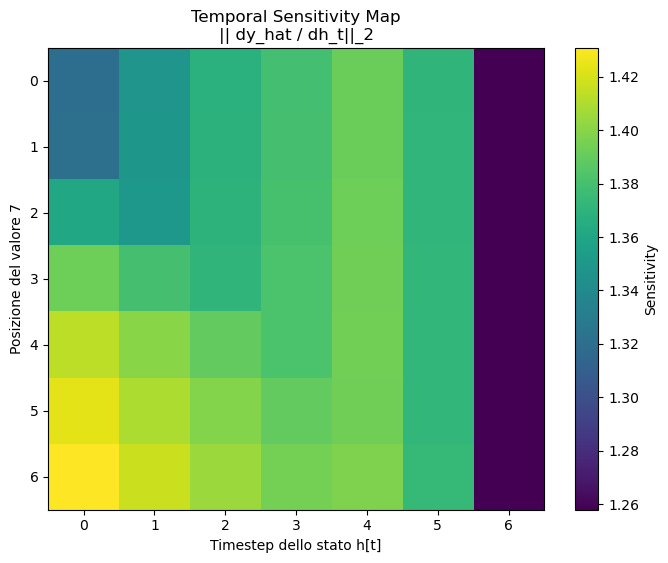

In [41]:
plt.figure(figsize=(8,6))

plt.imshow(S_matrix.numpy(), aspect="auto")
plt.xlabel("Timestep dello stato h[t]")
plt.ylabel("Posizione del valore 7")
plt.title("Temporal Sensitivity Map\n" "|| dy_hat / dh_t||_2")

plt.colorbar(label="Sensitivity")

plt.xticks(range(7))
plt.yticks(range(7))

plt.show()

In [42]:
memory_signal = []

for pos in range(7):
    value = S_matrix[pos, pos].item()
    memory_signal.append(value)

    print(f"Posizione {pos} | " f"Memory sensitivity = {value:.8f}")

Posizione 0 | Memory sensitivity = 1.32061625
Posizione 1 | Memory sensitivity = 1.34922683
Posizione 2 | Memory sensitivity = 1.36989760
Posizione 3 | Memory sensitivity = 1.38165247
Posizione 4 | Memory sensitivity = 1.39396429
Posizione 5 | Memory sensitivity = 1.37269604
Posizione 6 | Memory sensitivity = 1.25787520


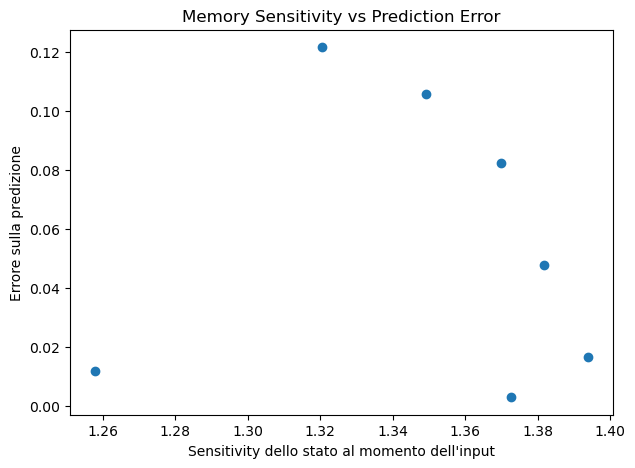

In [43]:
# Grafico dei segnali di memoria / errore
errors = torch.tensor([
    0.1217,
    0.1060,
    0.0823,
    0.0478,
    0.0166,
    0.0031,
    0.0121
])

plt.figure(figsize=(7, 5))

plt.scatter(memory_signal, errors.numpy())

plt.xlabel("Sensitivity dello stato al momento dell'input")
plt.ylabel("Errore sulla predizione")
plt.title("Memory Sensitivity vs Prediction Error")

plt.show()

In [44]:
# Correlazione
memory_tensor = torch.tensor(memory_signal)
corr = torch.corrcoef(torch.stack([memory_tensor, errors]))

print("Correlation:", corr[0, 1].item())

Correlation: -0.044036123901605606


In [45]:
# Stavolta introduciamo anche l'input, ovvero dy_hat / dx_p
def input_sensitivity(position, value=7.0):

    x_probe = torch.zeros(7, 1)
    x_probe[position, 0] = value / 9.0
    x_probe.requires_grad_(True)
    y_hat, states = forward_4d(x_probe)

    grad_x = torch.autograd.grad(y_hat, x_probe, retain_graph=True)[0]

    return grad_x.detach(), y_hat.detach()

In [46]:
for pos in range(7):
    grad_x, pred = input_sensitivity(pos)

    print(f"Pos {pos} | " f"dy_hat/dx_pos = {grad_x[pos].item():.8f} | " f"Pred = {pred.item()*9:.4f}")

Pos 0 | dy_hat/dx_pos = 0.90507185 | Pred = 7.1217
Pos 1 | dy_hat/dx_pos = 0.92976272 | Pred = 7.1060
Pos 2 | dy_hat/dx_pos = 0.94981909 | Pred = 7.0823
Pos 3 | dy_hat/dx_pos = 0.96520090 | Pred = 7.0478
Pos 4 | dy_hat/dx_pos = 0.97718740 | Pred = 7.0166
Pos 5 | dy_hat/dx_pos = 0.98785090 | Pred = 7.0031
Pos 6 | dy_hat/dx_pos = 0.99773842 | Pred = 6.9879


In [47]:
input_influence = []

for pos in range(7):
    grad_x, pred = input_sensitivity(pos)
    influence = abs(grad_x[pos].item())

    input_influence.append(influence)

    print(f"Posizione {pos} | " f"Input influence = {influence:.8f}")

Posizione 0 | Input influence = 0.90507185
Posizione 1 | Input influence = 0.92976272
Posizione 2 | Input influence = 0.94981909
Posizione 3 | Input influence = 0.96520090
Posizione 4 | Input influence = 0.97718740
Posizione 5 | Input influence = 0.98785090
Posizione 6 | Input influence = 0.99773842


In [49]:
print(errors.numpy())

[0.1217 0.106  0.0823 0.0478 0.0166 0.0031 0.0121]


In [50]:
influence_tensor = torch.tensor(input_influence)

corr = torch.corrcoef(torch.stack([influence_tensor, errors]))

print("Correlation:", corr[0, 1].item())

Correlation: -0.9701439142227173


In [54]:
# Ora analizziamo quanto una perturbazione dello stato in timestep p viene alterata quando raggiunge h_6
def transition_jacobians(x_probe):
    y_hat, states = forward_4d(x_probe)

    T = []

    for t in range(1, len(states)):
        h_prev = states[t - 1]

        def next_state(h):
            return torch.tanh(Wx @ x_probe[t] + Wh @ h + b)

        J_t = torch.autograd.functional.jacobian(next_state, h_prev)

        T.append(J_t.detach())

    return T

In [55]:
x_probe, _ = make_probe(position=0, value=7.0)
T = transition_jacobians(x_probe)

for t, J_t in enumerate(T, start=1):
    print(f"Timestep {t} | " f"||T_t|| = {torch.linalg.matrix_norm(J_t).item():.6f}")

Timestep 1 | ||T_t|| = 1.297800
Timestep 2 | ||T_t|| = 1.307191
Timestep 3 | ||T_t|| = 1.315122
Timestep 4 | ||T_t|| = 1.322314
Timestep 5 | ||T_t|| = 1.328932
Timestep 6 | ||T_t|| = 1.334970


In [56]:
# Ora aggiungiamo la capacità di seguire la direzione della perturbazione del 7. vi = T_iv_i-1, v_0 = dh_0/dx_0
def trace_input_signal(position=0, value=7.0):
    x_probe, _ = make_probe(position, value)

    x_probe.requires_grad_(True)

    y_hat, states = forward_4d(x_probe)

    # Jacobiana h_position rispetto a x_position
    def state_from_input(x_scalar):
        h = torch.zeros(hidden_size)
        for t in range(position + 1):
            x_t = (x_scalar if t == position else x_probe[t])

            h = torch.tanh(Wx @ x_t + Wh @ h + b)
        return h
    x_scalar = x_probe[position].detach().clone()
    x_scalar.requires_grad_(True)
    v = torch.autograd.functional.jacobian(state_from_input, x_scalar).squeeze()

    norms = [torch.linalg.vector_norm(v).item()]

    # propagazione attraverso gli stati successivi
    for t in range(position + 1, 7):
        h_prev = states[t - 1].detach()

        def next_state(h):
            return torch.tanh(Wx @ x_probe[t] + Wh @ h + b)

        T_t = torch.autograd.functional.jacobian(next_state, h_prev)

        v = T_t @ v

        norms.append(torch.linalg.vector_norm(v).item())

    return norms

In [57]:
norms = trace_input_signal(position=0, value=7.0)

for timestep, norm in enumerate(norms):
    print(f"h[{timestep}] | " f"Signal norm = {norm:.8f}")

h[0] | Signal norm = 0.78235662
h[1] | Signal norm = 0.76325202
h[2] | Signal norm = 0.75156420
h[3] | Signal norm = 0.74455637
h[4] | Signal norm = 0.74114674
h[5] | Signal norm = 0.74062842
h[6] | Signal norm = 0.74259967


## Significato delle grandezze ottenute
### v_t = dy_hat/dx_t: misura la direzione del cambiamento di h_t cambiando leggermente l'input x_t
### dy_hat/dh_t: misura quanto v_t è allineato con la direzione in cui l'output è sensibile.

In [58]:
# Funzione che conserva sia v_t che gli stati
def trace_signal_vectors(position=0, value=7.0):
    x_probe, _ = make_probe(position, value)
    x_probe.requires_grad_(True)
    y_hat, states = forward_4d(x_probe)

    # dh_position/ dx_position
    def state_from_input(x_scalar):
        h = torch.zeros(hidden_size)

        for t in range(position + 1):
            if t == position:
                x_t = x_scalar
            else:
                x_t = x_probe[t]

            h = torch.tanh(Wx @ x_t + Wh @ h + b)
        return h

    x_scalar = x_probe[position].detach().clone()
    x_scalar.requires_grad_(True)

    v = torch.autograd.functional.jacobian(state_from_input, x_scalar).squeeze()

    vectors = [v]

    for t in range(position + 1, 7):
        h_prev = states[t - 1].detach()

        def next_state(h):
            return torch.tanh(Wx @ x_probe[t] + Wh @ h + b)

        T_t = torch.autograd.functional.jacobian(next_state, h_prev)

        v = T_t @ v

        vectors.append(v)

    return x_probe, y_hat, states, vectors

In [59]:
x_probe, y_hat, states, vectors = trace_signal_vectors(position=0, value=7.0)

g_states = torch.autograd.grad(y_hat, states, retain_graph=True)

In [61]:
# Test
for t in range(7):
    v = vectors[t]
    g = g_states[t]

    signal_norm = torch.linalg.vector_norm(v)
    grad_norm = torch.linalg.vector_norm(g)

    transport = torch.dot(g, v)

    cosine = transport / (signal_norm * grad_norm + 1e-12)

    print(f"h[{t}] | " f"||g|| = {grad_norm.item():.6f} | " f"||v|| = {signal_norm.item():.6f} | " f"cos={cosine.item():.6f} | " f"g*v={transport.item():.6f}")

h[0] | ||g|| = 1.320616 | ||v|| = 0.782357 | cos=0.875995 | g*v=0.905072
h[1] | ||g|| = 1.348397 | ||v|| = 0.763252 | cos=0.879422 | g*v=0.905072
h[2] | ||g|| = 1.368177 | ||v|| = 0.751564 | cos=0.880187 | g*v=0.905072
h[3] | ||g|| = 1.379230 | ||v|| = 0.744556 | cos=0.881351 | g*v=0.905072
h[4] | ||g|| = 1.391690 | ||v|| = 0.741147 | cos=0.877479 | g*v=0.905072
h[5] | ||g|| = 1.371200 | ||v|| = 0.740628 | cos=0.891214 | g*v=0.905072
h[6] | ||g|| = 1.257875 | ||v|| = 0.742600 | cos=0.968926 | g*v=0.905072


# Cella 68: Come mai a 16 passi il gradiente è circa 1 mentre l'errore esplode?
## Necessario vedere se il fallimento è state/dynamics drift o gradient/sensitivity collapse (dopo)

In [69]:
def inspect_trajectory(seq_len, value=7.0):
    x_probe, _ = make_long_probe(seq_len, value)

    with torch.no_grad():
        pred, states = forward_rnn(x_probe)

    print(f"Prediction = {pred.item()*9:.6f}")
    print("\nTimestep | ||h_t||")

    for t, h in enumerate(states):
        print(f"{t:3d} | " f"{torch.linalg.vector_norm(h).item():.8f}")

In [70]:
inspect_trajectory(16)

Prediction = 2.904197

Timestep | ||h_t||
  0 | 0.70223665
  1 | 0.67842031
  2 | 0.63713557
  3 | 0.59862804
  4 | 0.56163698
  5 | 0.52506417
  6 | 0.48905218
  7 | 0.45362732
  8 | 0.41887930
  9 | 0.38500139
 10 | 0.35231438
 11 | 0.32131141
 12 | 0.29271930
 13 | 0.26756331
 14 | 0.24719669
 15 | 0.23321091


In [71]:
inspect_trajectory(64)

Prediction = -8.165135

Timestep | ||h_t||
  0 | 0.70223665
  1 | 0.67842031
  2 | 0.63713557
  3 | 0.59862804
  4 | 0.56163698
  5 | 0.52506417
  6 | 0.48905218
  7 | 0.45362732
  8 | 0.41887930
  9 | 0.38500139
 10 | 0.35231438
 11 | 0.32131141
 12 | 0.29271930
 13 | 0.26756331
 14 | 0.24719669
 15 | 0.23321091
 16 | 0.22712122
 17 | 0.22985101
 18 | 0.24132320
 19 | 0.26051173
 20 | 0.28588757
 21 | 0.31587654
 22 | 0.34910366
 23 | 0.38445011
 24 | 0.42102373
 25 | 0.45810905
 26 | 0.49512425
 27 | 0.53159076
 28 | 0.56711346
 29 | 0.60136914
 30 | 0.63409901
 31 | 0.66510391
 32 | 0.69424033
 33 | 0.72141623
 34 | 0.74658632
 35 | 0.76974648
 36 | 0.79092818
 37 | 0.81019199
 38 | 0.82762146
 39 | 0.84331709
 40 | 0.85739088
 41 | 0.86996138
 42 | 0.88115019
 43 | 0.89107782
 44 | 0.89986181
 45 | 0.90761465
 46 | 0.91444200
 47 | 0.92044276
 48 | 0.92570788
 49 | 0.93032044
 50 | 0.93435591
 51 | 0.93788230
 52 | 0.94096076
 53 | 0.94364566
 54 | 0.94598550
 55 | 0.94802332
 56 |

In [76]:
# Misuriamo anche quanto cambia la direzione dello stato
def inspect_state_drift(seq_len, value=7.0):
    x_probe, _ = make_long_probe(seq_len, value)

    with torch.no_grad():
        pred, states = forward_rnn(x_probe)

    h0 = states[0]

    print("Timestep | ||h_t|| | cos(h_t, h_0)")

    for t, h in enumerate(states):
        cosine = torch.dot(h, h0) / (torch.linalg.vector_norm(h) * torch.linalg.vector_norm(h0) +1e-12)
        print(f"{t:3d} | "
        f"{torch.linalg.vector_norm(h).item():.6f} | " f"{cosine.item():.6f}")

In [77]:
inspect_state_drift(16)

Timestep | ||h_t|| | cos(h_t, h_0)
  0 | 0.702237 | 1.000000
  1 | 0.678420 | 0.996389
  2 | 0.637136 | 0.994799
  3 | 0.598628 | 0.992634
  4 | 0.561637 | 0.989266
  5 | 0.525064 | 0.984518
  6 | 0.489052 | 0.977818
  7 | 0.453627 | 0.968381
  8 | 0.418879 | 0.955072
  9 | 0.385001 | 0.936201
 10 | 0.352314 | 0.909256
 11 | 0.321311 | 0.870541
 12 | 0.292719 | 0.814798
 13 | 0.267563 | 0.735131
 14 | 0.247197 | 0.624080
 15 | 0.233211 | 0.477042


In [78]:
inspect_state_drift(64)

Timestep | ||h_t|| | cos(h_t, h_0)
  0 | 0.702237 | 1.000000
  1 | 0.678420 | 0.996389
  2 | 0.637136 | 0.994799
  3 | 0.598628 | 0.992634
  4 | 0.561637 | 0.989266
  5 | 0.525064 | 0.984518
  6 | 0.489052 | 0.977818
  7 | 0.453627 | 0.968381
  8 | 0.418879 | 0.955072
  9 | 0.385001 | 0.936201
 10 | 0.352314 | 0.909256
 11 | 0.321311 | 0.870541
 12 | 0.292719 | 0.814798
 13 | 0.267563 | 0.735131
 14 | 0.247197 | 0.624080
 15 | 0.233211 | 0.477042
 16 | 0.227121 | 0.297977
 17 | 0.229851 | 0.102725
 18 | 0.241323 | -0.086408
 19 | 0.260512 | -0.251793
 20 | 0.285888 | -0.386410
 21 | 0.315877 | -0.491658
 22 | 0.349104 | -0.572607
 23 | 0.384450 | -0.634782
 24 | 0.421024 | -0.682864
 25 | 0.458109 | -0.720447
 26 | 0.495124 | -0.750177
 27 | 0.531591 | -0.773974
 28 | 0.567113 | -0.793234
 29 | 0.601369 | -0.808979
 30 | 0.634099 | -0.821965
 31 | 0.665104 | -0.832756
 32 | 0.694240 | -0.841784
 33 | 0.721416 | -0.849379
 34 | 0.746586 | -0.855799
 35 | 0.769746 | -0.861248
 36 | 0.790

## Cerchiamo dove il sistema si incarta, se si tratta di: 
### drift (g*v costante circa 1.007 ma stato autonomo dopo input si sposta verso una regione dello spazio nascosto che 
### produce un valore sbagliato.
### misalignment (cos(theta) tendente a 0, geometricamente il segnale è poco utile per readout
### vero vanishing transport (o ||g|| o ||v|| o |cos(theta)| tendono a 0

In [82]:
def transport_profile(seq_len, value=7.0):
    x_probe, _ = make_long_probe(seq_len, value)

    x_probe.requires_grad_(True)
    
    y_hat, states = forward_rnn(x_probe)

    rows = []

    for t, h in enumerate(states):
        # g_t = dy/dh_t
        g = torch.autograd.grad(y_hat, h, retain_graph=True)[0]

        # costruiamo v_t = dh_t/dx_0
        v_components = []

        for i in range(hidden_size):
            component = torch.autograd.grad(h[i], x_probe, retain_graph=True)[0][0, 0]

            v_components.append(component)

        v = torch.stack(v_components)
        g_norm = torch.linalg.vector_norm(g)
        v_norm = torch.linalg.vector_norm(v)

        dot = torch.dot(g, v)

        cosine = dot / (g_norm * v_norm + 1e-12)

        rows.append([
            t,
            g_norm.item(),
            v_norm.item(),
            cosine.item(),
            dot.item()
        ])

    return rows

In [83]:
rows16 = transport_profile(16)

print("t | ||g|| | ||v|| | cos | g*v")

for row in rows16:
    print(f"{row[0]:2d} | "
          f"{row[1]:.6f} | "
          f"{row[2]:.6f} | "
          f"{row[3]:.6f} | "
          f"{row[4]:.6f}")

t | ||g|| | ||v|| | cos | g*v
 0 | 1.469654 | 0.782357 | 0.875987 | 1.007204
 1 | 1.500512 | 0.763252 | 0.879448 | 1.007204
 2 | 1.523386 | 0.751564 | 0.879713 | 1.007204
 3 | 1.539140 | 0.744556 | 0.878904 | 1.007204
 4 | 1.548352 | 0.741147 | 0.877694 | 1.007204
 5 | 1.551656 | 0.740628 | 0.876438 | 1.007204
 6 | 1.549745 | 0.742600 | 0.875190 | 1.007204
 7 | 1.543338 | 0.746745 | 0.873945 | 1.007204
 8 | 1.533165 | 0.752768 | 0.872705 | 1.007204
 9 | 1.519995 | 0.760377 | 0.871457 | 1.007204
10 | 1.504641 | 0.769275 | 0.870167 | 1.007204
11 | 1.486836 | 0.779151 | 0.869426 | 1.007204
12 | 1.465945 | 0.789669 | 0.870071 | 1.007204
13 | 1.453480 | 0.800466 | 0.865696 | 1.007204
14 | 1.409742 | 0.811145 | 0.880804 | 1.007204
15 | 1.257875 | 0.821274 | 0.974971 | 1.007204


In [84]:
def probe_function(seq_len):
    results = []

    for raw_value in range(1, 10):
        x_probe = torch.zeros(seq_len, 1)
        x_probe[0, 0] = raw_value / 9.0

        with torch.no_grad():
            pred, _ = forward_rnn(x_probe)
        pred_original = pred.item() * 9.0

        results.append((raw_value, pred_original))

    return results

In [85]:
for T in [7, 16, 32, 64]:
    print(f"\nT = {T}")

    results = probe_function(T)

    for x_value, prediction in results:
        print(f"{x_value} -> {prediction:.5f}")


T = 7
1 -> 0.91922
2 -> 2.00230
3 -> 3.08702
4 -> 4.15617
5 -> 5.19368
6 -> 6.18577
7 -> 7.12168
8 -> 7.99400
9 -> 8.79861

T = 16
1 -> -3.48841
2 -> -2.53183
3 -> -1.48420
4 -> -0.37640
5 -> 0.75158
6 -> 1.85749
7 -> 2.90420
8 -> 3.86502
9 -> 4.72534

T = 32
1 -> -7.48625
2 -> -7.24946
3 -> -6.93715
4 -> -6.53280
5 -> -6.02494
6 -> -5.41352
7 -> -4.71483
8 -> -3.96107
9 -> -3.19300

T = 64
1 -> -8.20784
2 -> -8.20499
3 -> -8.20105
4 -> -8.19560
5 -> -8.18814
6 -> -8.17814
7 -> -8.16514
8 -> -8.14885
9 -> -8.12934


In [86]:
# Stima della pendenza e dell'intercetta
import numpy as np

In [87]:
for T in [7, 16, 32, 64]:
    results = probe_function(T)

    xs = np.array([r[0] for r in results])

    ys = np.array([r[1] for r in results])

    slope, intercept = np.polyfit(xs, ys, 1)
    print(f"T={T:3d} | " f"slope={slope:.5f} | " f"intercept={intercept:.5f}")

T=  7 | slope=0.99319 | intercept=0.08497
T= 16 | slope=1.05094 | intercept=-4.56326
T= 32 | slope=0.54337 | intercept=-8.44051
T= 64 | slope=0.00953 | intercept=-8.22754


In [88]:
def first_second_derivative(seq_len, raw_value=7.0):
    x_scalar = torch.tensor([raw_value / 9.0], requires_grad=True)

    def model_from_x(x):
        seq = torch.zeros(seq_len, 1)

        # evitiamo assegnamenti in-place problematici
        first = x.reshape(1, 1)

        if seq_len > 1:
            rest = torch.zeros(seq_len - 1, 1)
            seq = torch.cat([first, rest], dim=0)
        else:
            seq = first

        pred, _ = forward_rnn(seq)
        return pred.squeeze()

    y_local = model_from_x(x_scalar)
    first = torch.autograd.grad(y_local, x_scalar, create_graph=True)[0]

    second = torch.autograd.grad(first, x_scalar)[0]

    return (y_local.item(), first.item(), second.item())

In [89]:
for T in [7, 16, 32, 64, 128]:
    pred, d1, d2 = first_second_derivative(T, raw_value=7.0)
    print(f"T={T:3d} | " f"y={pred*9:.5f} | " f"dy/dx={d1:.8f} | " f"d2y/dx2={d2:.8f}")

T=  7 | y=7.12168 | dy/dx=0.90507185 | d2y/dx2=-0.57475519
T= 16 | y=2.90420 | dy/dx=1.00720382 | d2y/dx2=-0.78241861
T= 32 | y=-4.71483 | dy/dx=0.73264235 | d2y/dx2=0.50253659
T= 64 | y=-8.16514 | dy/dx=0.01462649 | d2y/dx2=0.02976128
T=128 | y=-8.21588 | dy/dx=0.00000158 | d2y/dx2=0.00000325


In [90]:
# Individuiamo l'attrattore
def long_trajectory(value=7.0, seq_len=300):
    x = torch.zeros(seq_len, 1)
    x[0, 0] = value / 9.0

    with torch.no_grad():
        pred, states = forward_rnn(x)

    outputs = []

    for h in states:
        y_t = Wy @ h + by
        outputs.append(y_t.item() * 9.0)

    return states, outputs

In [91]:
states_long, outputs_long = long_trajectory(value=7.0, seq_len=300)

for t in [0, 6, 15, 31, 63, 127, 199, 299]:
    print(f"t={t:3d} | " f"output={outputs_long[t]:.8f} | " f"||h||={torch.linalg.vector_norm(states_long[t]).item():.8f}")

t=  0 | output=9.70341253 | ||h||=0.70223665
t=  6 | output=7.12167746 | ||h||=0.48905218
t= 15 | output=2.90419722 | ||h||=0.23321091
t= 31 | output=-4.71483368 | ||h||=0.66510391
t= 63 | output=-8.16513509 | ||h||=0.95716798
t=127 | output=-8.21588355 | ||h||=0.96151102
t=199 | output=-8.21588570 | ||h||=0.96151119
t=299 | output=-8.21588570 | ||h||=0.96151119


In [92]:
h_star = states_long[-1]
with torch.no_grad():
    h_next = torch.tanh(Wh @ h_star + b)
    fixed_point_error = torch.linalg.vector_norm(h_next - h_star)

print("Fixed-point residual:", fixed_point_error.item())

Fixed-point residual: 0.0


In [94]:
# Test più forte
for value in [1.0, 3.0, 5.0, 7.0, 9.0]:
    _, outputs = long_trajectory(value=value, seq_len=300)
    print(f"Initial value={value:.0f} |" f"Final output={outputs[-1]:.8f}")

Initial value=1 |Final output=-8.21588570
Initial value=3 |Final output=-8.21588570
Initial value=5 |Final output=-8.21588570
Initial value=7 |Final output=-8.21588570
Initial value=9 |Final output=-8.21588570


# Quindi lo stato attraversa lo spazio hidden, cambia direzione e infine entra nel bacino attrattore h*
## Per studiare la stabilità del punto fisso dell'informazione, si calcolano ora gli autovalori
## J_F(h*) = diag(1 - (h*)**2)W_h
### Se tutti sono in modulo < 1, il punto fisso è localmente stabile.
### Se un autovalore ha modulo ~= 1, quella direzione conserva informazione molto più a lungo. 
### Se un autovalore ha modulo > 1, la dinamica è localmente instabile lungo quella direzione.

In [96]:
with torch.no_grad():
    D = torch.diag(1.0 - h_star**2)
    J_star = D @ Wh

eigvals = torch.linalg.eigvals(J_star)

print("Eigenvalues:")
for i, ev in enumerate(eigvals):
    print(i, ev.item())

print("\nModuli:")
for i, ev in enumerate(eigvals):
    print(i, abs(ev.item()))

Eigenvalues:
0 (0.8668916821479797+0j)
1 (-0.1790153533220291+0j)
2 (-0.04723622649908066+0.1903517246246338j)
3 (-0.04723622649908066-0.1903517246246338j)
4 (0.04204223304986954+0.05301779881119728j)
5 (0.04204223304986954-0.05301779881119728j)
6 (0.19804976880550385+0.006029350683093071j)
7 (0.19804976880550385-0.006029350683093071j)

Moduli:
0 0.8668916821479797
1 0.1790153533220291
2 0.19612506255306808
3 0.19612506255306808
4 0.06766414375874517
5 0.06766414375874517
6 0.19814152516212558
7 0.19814152516212558


In [97]:
spectral_radius = eigvals.abs().max().item()
print("Spectral radius:", spectral_radius)

Spectral radius: 0.8668916821479797


## Calcolo di valori singolari: 
### se sigma_max < 1 ogni perturbazione infinitesima si contrae in un singolo passo;
### se sigma_max > 1 esistono direzioni che vengono temporaneamente amplificate anche con autovalori in modulo < 1

In [98]:
singular_values = torch.linalg.svdvals(J_star)

print("Singular values:")
for i, s in enumerate(singular_values):
    print(i, s.item())

print("\nLargest singular value:", singular_values.max().item())

Singular values:
0 1.0207700729370117
1 0.3958972096443176
2 0.3405064344406128
3 0.2628355026245117
4 0.1760936975479126
5 0.1553862988948822
6 0.06658534705638885
7 0.016282981261610985

Largest singular value: 1.0207700729370117


In [99]:
# Non-normalità
non_normality = torch.linalg.matrix_norm(J_star.T @ J_star - J_star @ J_star.T)

print("Non-normality:", non_normality.item())

Non-normality: 0.7733275294303894


In [100]:
Jk = torch.eye(hidden_size)

print("k | ||J^k||_2")

for k in range(1, 101):
    Jk = J_star @ Jk

    norm = torch.linalg.matrix_norm(Jk, ord=2)

    if k in [1, 2, 4, 8, 16, 32, 64, 100]:
        print(f"{k:3d} | {norm.item():.10f}")

k | ||J^k||_2
  1 | 1.0207700729
  2 | 0.8988146782
  4 | 0.6714186668
  8 | 0.3793926835
 16 | 0.1210065931
 32 | 0.0123097319
 64 | 0.0001273877
100 | 0.0000007445


In [101]:
eigvals, eigvecs = torch.linalg.eig(J_star)
rank = torch.linalg.matrix_rank(eigvecs)
cond = torch.linalg.cond(eigvecs)

print("Rank eigenvectors:", rank.item())
print("Condition number P:", cond.item())

Rank eigenvectors: 8
Condition number P: 46.41059875488281


### Trovato il rango pari a 8, si conclude che J_star è diagonalizzabile ma k(P) dice anche che la diagonalizzazione non è ortogonale.
### Troviamo quale è l direzione che sopravvive più a lungo. Quella associata all'autovalore più grande.

In [102]:
eigvals, eigvecs = torch.linalg.eig(J_star)

idx = torch.argmax(eigvals.abs())

lambda_dom = eigvals[idx]
v_dom = eigvecs[:, idx]

print("Dominant eigenvalue:", lambda_dom)
print("Magnitude:", lambda_dom.abs().item())
print("Dominant eigenvector:")
print(v_dom)

Dominant eigenvalue: tensor(0.8669+0.j)
Magnitude: 0.8668916821479797
Dominant eigenvector:
tensor([ 0.3520+0.j, -0.3250+0.j, -0.3135+0.j,  0.3502+0.j,  0.4502+0.j,  0.3429+0.j,
        -0.3279+0.j,  0.3490+0.j])


# Come trovare il modo per conservare memoria per molti step?
### Se At = | cos(v_t,q_max) | sale rapidamente verso 1, la dinamica filtra le componenti più veloci e lascia
### solo la modalità dominante

In [110]:
x_probe, y_hat, states, vectors = trace_signal_vectors(position=0, value=7.0)

# Come trovare il modo per conservare memoria per molti step?
q = v_dom.real
q = q / torch.linalg.vector_norm(q)

print("t | ||v_t|| | ||q|| | |cos(v_t, q_dom)|")

for t, v in enumerate(vectors):
    cosine = torch.dot(v, q) / (torch.linalg.vector_norm(v) * torch.linalg.vector_norm(q) + 1e-12)
    print(f"{t:2d} | " f"{torch.linalg.vector_norm(v).item():.8f} | " f"{torch.linalg.vector_norm(q).item():.8f} | " f"{abs(cosine.item()):.8f}")
v6 = vectors[6]

#print("v6 =", v6)
#print("shape =", v6.shape)
#print("||v6|| =", torch.linalg.vector_norm(v6).item())

t | ||v_t|| | ||q|| | |cos(v_t, q_dom)|
 0 | 0.78235662 | 1.00000000 | 0.99376202
 1 | 0.76325202 | 1.00000000 | 0.99181896
 2 | 0.75156420 | 1.00000000 | 0.99062866
 3 | 0.74455637 | 1.00000000 | 0.99040025
 4 | 0.74114674 | 1.00000000 | 0.99066192
 5 | 0.74062842 | 1.00000000 | 0.99101853
 6 | 0.74259967 | 1.00000000 | 0.99139065


In [107]:
v_dom_real = v_dom.real

cos_memory_dom = torch.dot(v6, v_dom_real) / (torch.linalg.vector_norm(v6) * torch.linalg.vector_norm(v_dom_real) + 1e-12)

print("cos(memory, dominant mode) =", cos_memory_dom.item())

cos(memory, dominant mode) = 0.9913906455039978


In [119]:
x_probe, _ = make_long_probe(seq_len=64, value=7.0)

with torch.no_grad():
    pred, states = forward_rnn(x_probe)

### Rho(J_t): dinamica modale e asintotica a J_t costante
### sigma_max(J_t): massima amplificazione locale in un singolo step

In [112]:
spectral_radii = []
max_singular_values = []

for t, h in enumerate(states):
    D_t = torch.diag(1.0 - h**2)

    J_t = D_t @ Wh

    eigvals_t = torch.linalg.eigvals(J_t)
    rho_t = eigvals_t.abs().max()

    singular_t = torch.linalg.svdvals(J_t)

    sigma_t = singular_t.max()
    spectral_radii.append(rho_t.item())
    max_singular_values.append(sigma_t.item())

    print(f"t={t:2d} | " f"rho={rho_t.item():.6f} | " f"sigma_max={sigma_t.item():.6f}")

t= 0 | rho=0.973310 | sigma_max=1.099356
t= 1 | rho=0.979459 | sigma_max=1.105100
t= 2 | rho=0.984901 | sigma_max=1.113188
t= 3 | rho=0.989706 | sigma_max=1.120096
t= 4 | rho=0.993981 | sigma_max=1.126358
t= 5 | rho=0.997787 | sigma_max=1.132128
t= 6 | rho=1.001136 | sigma_max=1.137390
t= 7 | rho=1.004039 | sigma_max=1.142158
t= 8 | rho=1.006501 | sigma_max=1.146439
t= 9 | rho=1.008517 | sigma_max=1.150230
t=10 | rho=1.010085 | sigma_max=1.153524
t=11 | rho=1.011193 | sigma_max=1.156308
t=12 | rho=1.011828 | sigma_max=1.158567
t=13 | rho=1.011974 | sigma_max=1.160280
t=14 | rho=1.011616 | sigma_max=1.161426
t=15 | rho=1.010739 | sigma_max=1.161983
t=16 | rho=1.009331 | sigma_max=1.161931
t=17 | rho=1.007380 | sigma_max=1.161249
t=18 | rho=1.004883 | sigma_max=1.159927
t=19 | rho=1.001841 | sigma_max=1.157957
t=20 | rho=0.998265 | sigma_max=1.155341
t=21 | rho=0.994173 | sigma_max=1.152092
t=22 | rho=0.989596 | sigma_max=1.148233
t=23 | rho=0.984573 | sigma_max=1.143804
t=24 | rho=0.979

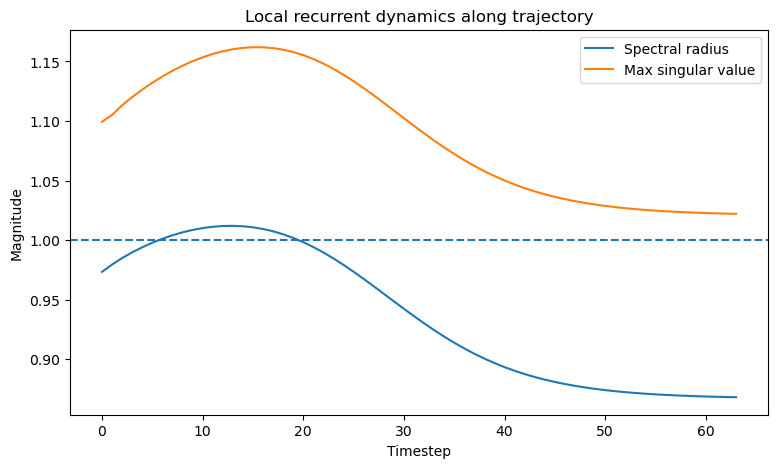

In [113]:
plt.figure(figsize=(9, 5))

plt.plot(spectral_radii, label="Spectral radius")
plt.plot(max_singular_values, label="Max singular value")

plt.axhline(1.0, linestyle="--")

plt.xlabel("Timestep")
plt.ylabel("Magnitude")
plt.title("Local recurrent dynamics along trajectory")

plt.legend()
plt.show()

## Memory encoding -> quasi-neutral/transient regime -> representation drift -> attractor capture -> memory extinction
# Costruire P_t = J_t * J_t-1 ... J_1

In [122]:
P = torch.eye(hidden_size)

cumulative_sigma_max = []
cumulative_sigma_min = []
cumulative_condition = []

for t in range(1, len(states)):
    h = states[t]
    D_t = torch.diag(1.0 - h**2)
    J_t = D_t @ Wh
    P = J_t @ P

    sv = torch.linalg.svdvals(P)

    sigma_max = sv.max().item()
    sigma_min = sv.min().item()

    condition = (sigma_max / sigma_min if sigma_min > 1e-12 else float("inf"))

    cumulative_sigma_max.append(sigma_max)
    cumulative_sigma_min.append(sigma_min)
    cumulative_condition.append(condition)

In [123]:
# Campioniamo
checkpoints = [1, 2, 4, 8, 16, 32, 63]

print("t | sigma_max(P) | sigma_min(P) | condition")

for t in checkpoints:
    i = t - 1
    print(f"{t:2d} | " f"{cumulative_sigma_max[i]:.8e} | " f"{cumulative_sigma_min[i]:.8e} | " f"{cumulative_condition[i]:.8e}")

t | sigma_max(P) | sigma_min(P) | condition
 1 | 1.10509956e+00 | 1.67873744e-02 | 6.58292079e+01
 2 | 1.09944081e+00 | 6.87107327e-04 | 1.60010055e+03
 4 | 1.08120298e+00 | 7.24102529e-06 | 1.49316283e+05
 8 | 1.09839547e+00 | 5.66723890e-10 | 1.93814922e+09
16 | 1.21165311e+00 | 1.53621366e-10 | 7.88726951e+09
32 | 8.02389562e-01 | 9.32485894e-11 | 8.60484397e+09
63 | 1.71269197e-02 | 1.55698837e-12 | 1.10000306e+10


### Sigma_min che collassa subito è indice del fatto che molte direzioni vengono distrutte rapidamente dalla RN, mentre una piccola parte sopravvive a lungo.

### Ora con la SVD: P_t = U_t Sigma_t V_t^T
#### Il primo r_t = V_t[:,0] indica la direzione dello stato iniziale che viene preservata/amplificata meglio fino a t

In [ ]:
def cumulative_memory_alignment(seq_len=64, value=7.0):
    x_probe, _ = make_long_probe(seq_len, value)
    x_probe.requires_grad_(True)
    y_hat, states = forward_rnn(x_probe)

    # v0 = dh0 / dx0
    v0_components = []
    for i in range(hidden_size):
        grad = torch.autograd.grad(states[0][i], x_probe, retain_graph=True)[0]
        v0_components.append(grad[0, 0])

    v0 = torch.stack(v0_components).detach()

    P = torch.eye(hidden_size)
    rows = []

    for t in range(1, seq_len):
        h = states[t].detach()
        D_t = torch.diag(1.0 - h**2)

        J_t = D_t @ Wh.detach()

        P = J_t @ P

        U, S, Vh = torch.linalg.svd(P)

        # right singular vector associato a sigma_max
        r_dom = Vh[0, :]

        cosine = torch.dot(v0, r_dom) / (torch.linalg.vector_norm(v0) * torch.linalg.vector_norm(r_dom) + 1e-12)

        rows.append([t, S[0].item(), S[-1].item(), abs(cosine.item())])

    return rows

In [128]:
rows = cumulative_memory_alignment(seq_len=64, value=7.0)

print("t | sigma_max | sigma_min | |cos(v0, best direction)|")
for row in rows:
    if row[0] in [1, 2, 4, 8, 16, 32, 63]:
        print(f"{row[0]:2d} | "
              f"{row[1]:.8e} | "
            f"{row[2]:.8e} | "
            f"{row[3]:.8f}"
        )

t | sigma_max | sigma_min | |cos(v0, best direction)|
 1 | 1.10509956e+00 | 1.67873744e-02 | 0.87624508
 2 | 1.09944081e+00 | 6.87107327e-04 | 0.87329203
 4 | 1.08120298e+00 | 7.24102529e-06 | 0.87617552
 8 | 1.09839547e+00 | 5.66723890e-10 | 0.87598634
16 | 1.21165311e+00 | 1.53621366e-10 | 0.87598652
32 | 8.02389562e-01 | 9.32485894e-11 | 0.87598652
63 | 1.71269197e-02 | 1.55698837e-12 | 0.87598670


# Quante dimensioni effettivamente sopravvivono, anche per sigma_min piccolo?
### Normalizziamo i valori di sigma p_i = sigma_i / sums_j(sigma_j)
### e calcoliamo H = -sums(i)(p_i log(p_i))

In [130]:
def effective_rank(singular_values):
    p = singular_values / singular_values.sum()
    entropy = -torch.sum(p * torch.log(p + 1e-12))

    return torch.exp(entropy)

In [131]:
def cumulative_memory_alignment(seq_len=64, value=7.0):
    x_probe, _ = make_long_probe(seq_len, value)
    x_probe.requires_grad_(True)
    y_hat, states = forward_rnn(x_probe)

    # v0 = dh0 / dx0
    v0_components = []
    ranks_eff = []
    for i in range(hidden_size):
        grad = torch.autograd.grad(states[0][i], x_probe, retain_graph=True)[0]
        v0_components.append(grad[0, 0])

    v0 = torch.stack(v0_components).detach()

    P = torch.eye(hidden_size)
    rows = []

    for t in range(1, seq_len):
        h = states[t].detach()
        D_t = torch.diag(1.0 - h**2)

        J_t = D_t @ Wh.detach()

        P = J_t @ P

        U, S, Vh = torch.linalg.svd(P)
        rank_eff = effective_rank(S)
        ranks_eff.append(rank_eff.item())

        # right singular vector associato a sigma_max
        r_dom = Vh[0, :]

        cosine = torch.dot(v0, r_dom) / (torch.linalg.vector_norm(v0) * torch.linalg.vector_norm(r_dom) + 1e-12)

        rows.append([t, S[0].item(), S[-1].item(), abs(cosine.item()), rank_eff])

    return rows

In [132]:
rows = cumulative_memory_alignment(seq_len=64, value=7.0)

print("t | sigma_max | sigma_min | |cos(v0, best direction)| | rank_eff")
for row in rows:
    if row[0] in [1, 2, 4, 8, 16, 32, 63]:
        print(f"{row[0]:2d} | "
              f"{row[1]:.8e} | "
            f"{row[2]:.8e} | "
            f"{row[3]:.8f} | "
            f"{row[4]:.8f}"
        )

t | sigma_max | sigma_min | |cos(v0, best direction)| | rank_eff
 1 | 1.10509956e+00 | 1.67873744e-02 | 0.87624508 | 5.30532980
 2 | 1.09944081e+00 | 6.87107327e-04 | 0.87329203 | 2.55327010
 4 | 1.08120298e+00 | 7.24102529e-06 | 0.87617552 | 1.10784185
 8 | 1.09839547e+00 | 5.66723890e-10 | 0.87598634 | 1.00057161
16 | 1.21165311e+00 | 1.53621366e-10 | 0.87598652 | 1.00000155
32 | 8.02389562e-01 | 9.32485894e-11 | 0.87598652 | 1.00000226
63 | 1.71269197e-02 | 1.55698837e-12 | 0.87598670 | 1.00000262
